# 5. Modelo original A+B v2

## 5.1 Motivación

El EDA (capítulo 2) muestra cuatro rasgos del conteo mensual de sismos por celda: **exceso de ceros**,
**sobredispersión**, **persistencia** y **heterogeneidad entre celdas**. Ningún modelo benchmark es el mejor en todas
las situaciones: los árboles aprovechan la actividad reciente en celdas activas, mientras que en celdas casi
inactivas una tasa base o un modelo de conteos es más estable. De ahí las dos ideas del modelo:

- **B:** un boosting cuya pérdida es la verosimilitud **binomial negativa inflada en ceros (ZINB)**, que modela a la vez
  la probabilidad de un cero estructural y la media de la parte de conteo, y devuelve exactamente la cantidad que
  minimiza el RMSLE, E[log(1 + Y)].
- **A:** un combinador que decide **cuánto confiar en cada pronosticador según el contexto de cada celda-mes**, con
  pesos softmax que dependen de meta-características (actividad reciente, excitación, perfil de los últimos 12 meses,
  magnitud máxima y estación), seguido de una calibración final.

In [1]:
# Localiza la raíz del proyecto (la carpeta con src/ y app.py) para poder importar los módulos de src/
import sys
from pathlib import Path
raiz = Path.cwd().resolve()
while not ((raiz / "src").is_dir() and (raiz / "app.py").exists()):
    raiz = raiz.parent
sys.path.insert(0, str(raiz))
# Librerías de análisis y módulos propios: configuración, datos, EDA, evaluación y utilidades del libro
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from src import config as cfg, datos, eda, evaluacion as ev
from src.libro import md, tabla, mostrar_plotly
from src.eda import es, p_fmt
# Estilo común de los gráficos, semilla global (SEMILLA = 42) y formato de las tablas
eda.configurar_graficos()
cfg.fijar_semillas()
pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 40)

## 5.2 Formulación matemática

**Distribución ZINB.** Para la celda-mes *i*, con media de conteo μ_i, probabilidad de cero estructural π_i y
dispersión α > 0:

$$
P(Y_i = 0) = \pi_i + (1-\pi_i)\,(1+\alpha\mu_i)^{-1/\alpha}, \qquad
P(Y_i = k) = (1-\pi_i)\,\frac{\Gamma(k+1/\alpha)}{\Gamma(1/\alpha)\,k!}\Big(\frac{1}{1+\alpha\mu_i}\Big)^{1/\alpha}\Big(\frac{\alpha\mu_i}{1+\alpha\mu_i}\Big)^{k},\ k\ge 1
$$ (ec-zinb)

**Modelo B (boosting de dos predictores).** μ_i = e^{η_i} y π_i = σ(ξ_i), con predictores aditivos en árboles:

$$
\eta(x) = \eta_0 + \nu \sum_{m=1}^{M} h_m(x), \qquad \xi(x) = \xi_0 + \nu \sum_{m=1}^{M} g_m(x)
$$ (ec-aditivo)

Cada árbol se ajusta con un **paso de Newton**: con gradiente $g_i = \partial \ell_i/\partial \eta_i$ y hessiano
$h_i = \partial^2 \ell_i/\partial \eta_i^2$ de la log-verosimilitud negativa ℓ, la aproximación de segundo orden
$\ell_i(\eta_i + c) \approx \ell_i + g_i c + \tfrac12 h_i c^2 = \tfrac12 h_i (c + g_i/h_i)^2 + \text{cte}$ implica que

$$
h_m = \arg\min_{h \in \mathcal{T}_{D,m}} \sum_i h_i \big(r_i - h(x_i)\big)^2, \qquad r_i = -g_i/h_i
$$ (ec-newton)

es decir, un árbol de regresión **ponderado por el hessiano** ajustado al paso de Newton (lo mismo para ξ). La
dispersión α se re-estima por máxima verosimilitud cada 20 iteraciones y M se elige por parada temprana con el 20 %
final de los meses. La salida de B es el pronóstico óptimo para el RMSLE bajo la ZINB:

$$
f_B(x) = \mathbb{E}[\log(1+Y)\mid x] = \sum_{k\ge 0} \log(1+k)\,P(Y=k \mid \mu(x),\pi(x),\alpha)
$$ (ec-elog)

**Árbol CART propio.** Para un nodo con filas S, el corte (j, k) maximiza

$$
G(j,k) = \frac{Y_L^2}{W_L} + \frac{Y_R^2}{W_R}, \qquad W = \sum w_i,\ Y = \sum w_i r_i
$$ (ec-ganancia)

**Combinador A.** Con K pronósticos f_j(x_i) en escala log1p y meta-características z_i (con constante):

$$
w_j(z) = \frac{\exp(z^\top \theta_j)}{\sum_{l=1}^K \exp(z^\top \theta_l)}, \qquad \hat\ell_A(x,z) = \sum_{j=1}^K w_j(z)\, f_j(x)
$$ (ec-softmax)

$$
J(\Theta) = \frac1n \sum_{i=1}^n \big(\hat\ell_A(x_i,z_i) - \log(1+y_i)\big)^2 + \lambda \lVert \Theta_{-0} \rVert^2
$$ (ec-objetivo)

Con s_{ik} = z_i^⊤θ_k, la derivada del softmax da $\partial \hat\ell_i/\partial s_{ik} = w_{ik}(f_{ik} - \hat\ell_i)$ y, por la
regla de la cadena, el **gradiente analítico** que usa L-BFGS:

$$
\frac{\partial J}{\partial \theta_k} = \frac{2}{n}\sum_{i=1}^n (\hat\ell_i - \log(1+y_i))\, w_{ik}\,(f_{ik} - \hat\ell_i)\, z_i + 2\lambda\,\theta_k^{(-0)}
$$ (ec-gradiente)

**Calibración final (Mincer-Zarnowitz).** Con el combinador ajustado en el 80 % inicial de los meses y evaluado en el
20 % final, (c₀, c₁) = MCO de log(1 + y) sobre ℓ̂_A, y el pronóstico es

$$
\hat y = \exp\!\big(\max(0,\ c_0 + c_1\,\hat\ell_A)\big) - 1
$$ (ec-calibracion)

## 5.3 Pseudocódigo

In [2]:
import sys
from src.original_model import PSEUDOCODIGO
print(PSEUDOCODIGO)

Algoritmo A+B v2  (entrada: panel de entrenamiento {(x_i, z_i, y_i)} ordenado por mes; salida: ŷ para filas nuevas)
 1. Para cada miembro j (10 benchmarks optimizados, núcleo ZINB, B, persistencia, estacional):
      dividir los meses en 5 bloques contiguos; para f = 1..4 entrenar j con los meses < inicio del bloque f − 1
      y predecir el bloque f  →  f_j(x_i) en escala log1p (predicciones fuera de pliegue cronológicas)
 2. Modelo B (boosting ZINB):  η ← log ȳ, ξ ← −0,8, α ← 1
      repetir m = 1..M:  g, h ← gradiente y hessiano de la NLL ZINB respecto de η
                         ajustar árbol CART propio a −g/h con pesos h;  η ← η + ν·árbol(x)
                         ídem para ξ (logit de cero estructural);  cada 20 iteraciones re-estimar α
      M = argmin de la NLL en el 20 % final de los meses (parada temprana cronológica)
      salida: E[log(1+Y)] bajo ZINB(μ = e^η, π = σ(ξ), α)
 3. Combinador A:  w(z) = softmax(zᵀΘ);  Θ = argmin Σ (Σ_j w_j(z_i) f_j(x_i) − log(1+y_i))² + λ‖Θ

## 5.4 Propiedades demostradas

**Proposición 1 (cota de error del combinador).** Para toda fila, $\min_j f_j \le \hat\ell_A \le \max_j f_j$ y

$$
\big(\hat\ell_A - \ell\big)^2 \le \sum_{j} w_j(z)\,\big(f_j - \ell\big)^2 .
$$ (ec-cota)

*Demostración.* Los pesos softmax son positivos y suman 1, así que ℓ̂_A es una combinación convexa de los f_j y está
en su envolvente convexa (primera afirmación). La función φ(u) = (u − ℓ)² es convexa; por la desigualdad de Jensen,
φ(Σ w_j f_j) ≤ Σ w_j φ(f_j). ∎

*Consecuencia.* Antes de la calibración, el error cuadrático de A en cada celda-mes nunca supera el promedio, ponderado
por los propios pesos, de los errores de sus miembros; la ganancia frente a ese promedio es exactamente la varianza
ponderada de los pronósticos, Σ w_j (f_j − ℓ̂_A)² (descomposición de ambigüedad de Krogh y Vedelsby).

**Proposición 2 (paso de Newton óptimo por hoja).** Dada la partición de un árbol, el valor de hoja
$c_S = \sum_{S} h_i r_i / \sum_S h_i$ minimiza la aproximación de segundo orden de la pérdida en la hoja.

*Demostración.* En la hoja S, $\sum_{i\in S}[g_i c + \tfrac12 h_i c^2]$ es una parábola en c con coeficiente
$\tfrac12\sum h_i > 0$ (el hessiano de la NLL ZINB respecto de η es positivo); su mínimo está en
$c = -\sum g_i / \sum h_i = \sum h_i r_i/\sum h_i$, que es la media ponderada que asigna el árbol de la ecuación
{eq}`ec-newton`. ∎

**Proposición 3 (terminación y complejidad del CART propio).** El algoritmo termina y crea a lo sumo $2^{D+1}-1$ nodos;
su costo es $O(p\,n\log n)$ para el orden inicial más $O(D\,p\,n)$ para las sumas acumuladas.

*Demostración.* Cada corte válido deja al menos m ≥ 1 filas a cada lado y la profundidad está acotada por D: el árbol es
binario de altura ≤ D, con a lo sumo 2^{D+1} − 1 nodos. En cada nivel, las filas de los nodos forman una partición de
las n filas; para cada variable se recorren en el orden precalculado (O(n) por variable con una máscara) y las sumas
acumuladas evalúan todos los cortes en O(n): O(p n) por nivel y O(D p n) en total. El orden inicial cuesta
O(p n log n) y se reutiliza en las 2M iteraciones del boosting. ∎

**Proposición 4 (la calibración es una proyección).** En el conjunto de calibración, los residuos de
{eq}`ec-calibracion` (antes del recorte en 0) tienen media cero y, si se repite la regresión de Mincer-Zarnowitz sobre el
pronóstico calibrado, se obtiene exactamente (c₀, c₁) = (0, 1).

*Demostración.* Es MCO con intercepto: las ecuaciones normales imponen Σ e_i = 0 y Σ e_i ℓ̂_i = 0. El pronóstico
calibrado es una función afín de ℓ̂, así que su regresión sobre sí mismo reproduce los ajustados con pendiente 1 e
intercepto 0 (la proyección es idempotente). ∎

## 5.5 Complejidad asintótica y tiempos medidos

| Componente | Entrenamiento | Inferencia (por fila) |
|---|---|---|
| Árbol CART propio | O(p n log n) + O(D p n) | O(D) |
| Modelo B (M iteraciones, 2 árboles cada una) | O(p n log n + M D p n) | O(M D) |
| Combinador A (T iteraciones de L-BFGS) | O(T n d K) | O(d K) |
| Calibración | O(n) | O(1) |
| A+B completo | 5 × (costo de los miembros) + lo anterior | Σ miembros + O(M D + d K) |

con n filas, p variables, D profundidad, d meta-características y K miembros. Por la Proposición 3 se espera que el
tiempo del árbol crezca casi linealmente con n (con un factor log n en el orden inicial) y linealmente con p.

,componente,varía,exponente empírico,esperado
0,combinador A (L-BFGS),n,"0,65","≤ 1 (T·n·d·K, con T variable)"
1,árbol CART (con orden reutilizado),n,"1,13",≈ 1 (lineal)
2,árbol CART (con orden reutilizado),p,"1,02",≈ 1 (lineal)
3,árbol CART (sin orden previo),n,"1,14","≈ 1 a 1,1 (n log n)"


**Lectura.** El árbol CART crece casi linealmente con n (exponente 1.13; el factor log n del orden explica que supere ligeramente 1) y linealmente con p (1.02), como predice la Proposición 3. El combinador crece de forma sublineal en el rango medido (0.65): el costo por iteración es lineal en n, pero el número de iteraciones de L-BFGS no es fijo y hay un costo constante de arranque que pesa más con n pequeño.

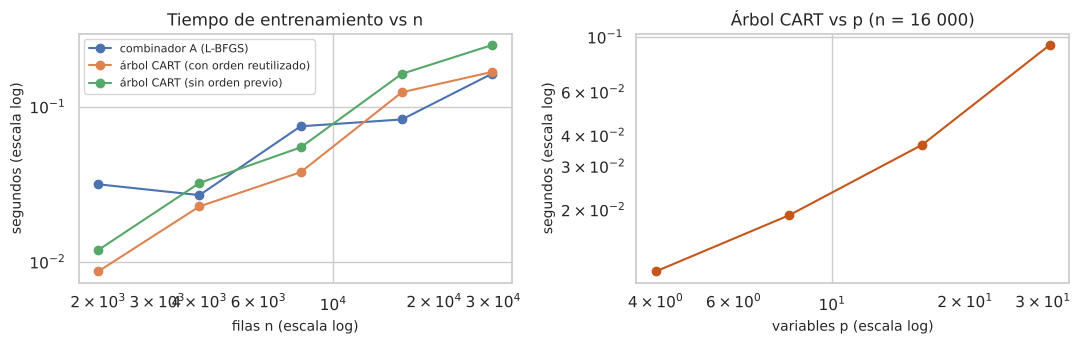

In [3]:
C = pd.read_csv(cfg.RESULTADOS / "e3" / "complejidad.csv")
filas = []
for (c, v), d in C.groupby(["componente", "variable"]):
    b = np.polyfit(np.log(d.valor), np.log(d.segundos), 1)[0]
    esperado = {"árbol CART (sin orden previo)": "≈ 1 a 1,1 (n log n)", "árbol CART (con orden reutilizado)": "≈ 1 (lineal)",
                "combinador A (L-BFGS)": "≤ 1 (T·n·d·K, con T variable)"}[c]
    filas.append({"componente": c, "varía": v, "exponente empírico": b, "esperado": esperado})
E = pd.DataFrame(filas)
display(tabla(E, dec=2))
g = lambda c, v: E[(E.componente == c) & (E["varía"] == v)]["exponente empírico"].iloc[0]  # noqa: E731
md(f"**Lectura.** El árbol CART crece casi linealmente con n (exponente {g('árbol CART (con orden reutilizado)', 'n'):.2f}; el "
   f"factor log n del orden explica que supere ligeramente 1) y linealmente con p ({g('árbol CART (con orden reutilizado)', 'p'):.2f}), "
   f"como predice la Proposición 3. El combinador crece de forma sublineal en el rango medido "
   f"({g('combinador A (L-BFGS)', 'n'):.2f}): el costo por iteración es lineal en n, pero el número de iteraciones de L-BFGS "
   f"no es fijo y hay un costo constante de arranque que pesa más con n pequeño.")
fig, axs = plt.subplots(1, 2, figsize=(11, 3.6))
for c, d in C[C.variable == "n"].groupby("componente"):
    axs[0].loglog(d.valor, d.segundos, "o-", label=c)
axs[0].set(xlabel="filas n (escala log)", ylabel="segundos (escala log)", title="Tiempo de entrenamiento vs n"); axs[0].legend(fontsize=8)
d = C[C.variable == "p"]
axs[1].loglog(d.valor, d.segundos, "o-", color="#c4561b")
axs[1].set(xlabel="variables p (escala log)", ylabel="segundos (escala log)", title="Árbol CART vs p (n = 16 000)")
plt.tight_layout(); plt.show()

## 5.6 Implementación

| Pieza | Archivo | Qué programa el proyecto |
|---|---|---|
| Árbol CART ponderado | `src/arbol_cart.py` | búsqueda exacta de cortes con sumas acumuladas, desempates con semilla, inferencia |
| Boosting ZINB (B) | `src/propuesto.py` (`BoostingZINB`, `grads_zinb`) | gradientes y hessianos analíticos, pasos de Newton, dispersión, parada temprana |
| Núcleo ZINB | `src/propuesto.py` (`ZINB`) | verosimilitud y gradiente analíticos, L-BFGS |
| Combinador (A) | `src/propuesto.py` (`CombinadorSoftmax`) | objetivo {eq}`ec-objetivo` y gradiente {eq}`ec-gradiente` |
| Clase scikit-learn | `src/original_model.py` (`ModeloOriginalAB`) | `fit`/`predict`, OOF cronológico, elección de λ, calibración, `explicar` |

Fragmentos centrales (código comentado en los archivos):

In [4]:
import inspect
from src import propuesto, arbol_cart
print(inspect.getsource(propuesto.CombinadorSoftmax))

class CombinadorSoftmax:
    """Combinador contextual: pesos softmax que dependen del estado de cada celda.

    El pronóstico es ``Σ_k w_k(z) b_k`` con ``w(z) = softmax(z T)``; se minimiza el error cuadrático en escala log1p más
    una penalización L2 sobre ``T`` (sin la fila del intercepto), con gradiente analítico y L-BFGS-B.

    Parameters
    ----------
    l2 : float
        Peso de la penalización L2 (λ).
    """
    def __init__(self, l2=1e-2):
        self.l2 = l2

    def _f(self, th, Z, B, y):
        d, K = Z.shape[1], B.shape[1]
        T = th.reshape(d, K)
        W = softmax(Z @ T, axis=1)
        pred = (W * B).sum(1)
        r = pred - y
        n = len(y)
        pen = self.l2 * np.sum(T[1:] ** 2)
        f = np.mean(r ** 2) + pen
        dlog = (2 * r / n)[:, None] * W * (B - pred[:, None])
        G = Z.T @ dlog
        G[1:] += 2 * self.l2 * T[1:]
        return f, G.ravel()

    def fit(self, Z, B, y):
        """Ajusta la matriz de pesos ``T``.

        Paramet

In [5]:
print(inspect.getsource(arbol_cart.ArbolCART._crecer))

    def _crecer(self, XT, y, w, O, mask, prof, n_const):
        Wn = w[mask].sum()
        Yn = (w[mask] * y[mask]).sum()
        nodo = self._nuevo(Yn / Wn)
        n = int(mask.sum())
        m = self.min_samples_leaf
        impureza = (w[mask] * y[mask] ** 2).sum() / Wn - (Yn / Wn) ** 2
        if prof >= self.max_depth or n < 2 * m or n < 2 or impureza <= _EPS:
            return nodo
        p = XT.shape[0]
        S = O[mask[O]].reshape(p, n)                          # filas del nodo ordenadas por cada variable
        xs = np.take_along_axis(XT, S, axis=1)
        ws, ys = w[S], y[S]
        WL = np.cumsum(ws, axis=1)[:, :-1]
        YL = np.cumsum(ws * ys, axis=1)[:, :-1]
        WR, YR = Wn - WL, Yn - YL
        pos = np.arange(1, n)                                 # filas a la izquierda si se corta tras la posición i
        valido = (xs[:, 1:] > xs[:, :-1] + _UMBRAL_CONSTANTE) & (pos >= m) & (n - pos >= m)
        with np.errstate(divide="ignore", invalid="ignore"):
      

## 5.7 Pruebas unitarias

`tests/test_original_model.py` verifica las cuatro propiedades exigidas: (i) aprende en datos sintéticos con solución
conocida, (ii) reproducibilidad con la misma semilla, (iii) entradas inválidas y (iv) `sklearn.base.clone`; además,
que los pesos suman 1 y que la explicación reproduce la predicción. `tests/test_arbol_cart.py` verifica el árbol (escalón
conocido, coincidencia con CART de referencia, semilla, restricciones y entradas inválidas) y `tests/test_artefactos.py`
la prueba de ida y vuelta.

In [6]:
import subprocess
r = subprocess.run([sys.executable, "-m", "pytest", "-q", "tests/test_original_model.py", "tests/test_arbol_cart.py", "tests/test_artefactos.py"],
                   cwd=cfg.RAIZ, capture_output=True, text=True)
print(r.stdout[-1500:])

## 5.8 Equivalencia con el modelo evaluado

`scripts/verificar_modelo_original.py` ajusta la clase con el entrenamiento del origen 2021 y compara sus predicciones
de 2021 con las del procedimiento evaluado en el origen móvil.

In [7]:
import json
v = json.load(open(cfg.RESULTADOS / "e3" / "verificacion_clase.json"))
md(f"RMSLE 2021 de la clase: **{v['rmsle_clase']:.5f}**; del procedimiento evaluado: **{v['rmsle_evaluado']:.5f}**; "
   f"repetir el propio procedimiento evaluado da {v['rmsle_repeticion_procedimiento']:.5f}. Las entradas de entrenamiento del "
   f"combinador (pronósticos fuera de pliegue de los 14 miembros y meta-características) coinciden bit a bit; las diferencias en "
   f"la prueba (máximo {v['dif_max']:.2f} sismos en una celda-mes; {v['dif_max_repeticion_procedimiento']:.2f} al repetir el "
   f"procedimiento) vienen del redondeo en las optimizaciones L-BFGS del núcleo ZINB y del combinador, que depende del número de "
   f"hilos del álgebra lineal. El efecto sobre el RMSLE es menor que 0,0001.")

RMSLE 2021 de la clase: **0.31490**; del procedimiento evaluado: **0.31493**; repetir el propio procedimiento evaluado da 0.31491. Las entradas de entrenamiento del combinador (pronósticos fuera de pliegue de los 14 miembros y meta-características) coinciden bit a bit; las diferencias en la prueba (máximo 0.34 sismos en una celda-mes; 0.29 al repetir el procedimiento) vienen del redondeo en las optimizaciones L-BFGS del núcleo ZINB y del combinador, que depende del número de hilos del álgebra lineal. El efecto sobre el RMSLE es menor que 0,0001.

## 5.9 Hiperparámetros del modelo propio

- **λ del combinador**: búsqueda en rejilla {0,001; 0,01; 0,1; 1} dentro de cada ventana de entrenamiento (bucle
  interno: 80 % / 20 % de los meses); el origen móvil es el bucle externo.
- **B**: optimización bayesiana (TPE, Optuna) de la tasa ν, la profundidad y el mínimo de filas por hoja, con 15
  evaluaciones y validación temporal interna de 3 pliegues sobre datos anteriores a 2016 (el mismo protocolo y presupuesto
  que los benchmarks; `scripts/optimizar_B_tpe.py`). La configuración usada hasta entonces (0,08 · 3 · 50) entró como
  primer candidato.
- **Decisión a nivel del modelo completo** (`scripts/comparar_B_validacion.py`), con una regla fijada antes de ejecutarla:
  adoptar la B optimizada solo si A+B con ella supera con significancia (Diebold-Mariano, p < 0,05) al A+B actual y a
  XGBoost · AG en la validación previa (< 2021). Ningún mes de 2021–2026 interviene.
- **Miembros**: hiperparámetros de los benchmarks fijados con datos anteriores a 2016.

,evaluación,RMSLE validación < 2016,ν,profundidad,filas por hoja
1,1,"0,3931","0,0551",6,119
12,12,"0,3934","0,0523",4,106
7,7,"0,3938","0,0644",3,79
11,11,"0,3944","0,0512",5,120
6,6,"0,3945","0,0329",3,58
5,5,"0,3951","0,1906",3,18
13,13,"0,3956","0,2747",5,138
8,8,"0,3960","0,0292",3,34
0,0,"0,3984","0,0800",3,50
2,2,"0,3988","0,1012",2,16


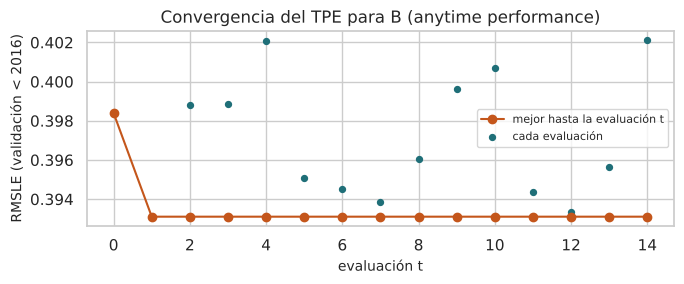

,rival,RMSLE rival,RMSLE A+B con B optimizada,dif. pérdida (rival − nuevo),p DM,nuevo mejor y significativo
0,"A+B actual (B 0,08 · 3 · 50)","0,3143","0,3151","-0,0005","0,0028",False
1,XGBoost · AG,"0,3143","0,3151","-0,0006","0,2628",False


**Decisión:** se conserva la B actual (ν = 0,08, profundidad 3, 50 filas por hoja). La B optimizada es mejor como modelo individual en la validación anterior a 2016, pero dentro de A+B empeora la validación previa (0.3151 frente a 0.3143; p = 0.003): lo que importa para la combinación no es el error de B sola, sino cuánto información nueva aporta respecto de los demás miembros.

In [8]:
import json
H = pd.read_csv(cfg.RESULTADOS / "e3" / "optimizacion_B_tpe.csv").rename(columns={"number": "evaluación", "value": "RMSLE validación < 2016",
        "params_lr": "ν", "params_depth": "profundidad", "params_min_leaf": "filas por hoja"})
display(tabla(H.sort_values("RMSLE validación < 2016"), dec=4))
fig, ax = plt.subplots(figsize=(7, 3))
ax.plot(H["evaluación"], H["RMSLE validación < 2016"].cummin(), "-o", color="#c4561b", label="mejor hasta la evaluación t")
ax.scatter(H["evaluación"], H["RMSLE validación < 2016"], color="#1f6f78", s=18, label="cada evaluación")
ax.set(xlabel="evaluación t", ylabel="RMSLE (validación < 2016)", title="Convergencia del TPE para B (anytime performance)"); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()
DB = pd.read_csv(cfg.RESULTADOS / "e3" / "decision_B_validacion.csv")
display(tabla(DB, dec=4))
dj = json.load(open(cfg.RESULTADOS / "e3" / "decision_B_validacion.json"))
md(f"**Decisión:** {'se adopta la B optimizada' if dj['adoptar_B_optimizada'] else 'se conserva la B actual (ν = 0,08, profundidad 3, 50 filas por hoja)'}. "
   f"La B optimizada es mejor como modelo individual en la validación anterior a 2016, pero dentro de A+B empeora la validación "
   f"previa ({DB['RMSLE A+B con B optimizada'].iloc[0]:.4f} frente a {DB['RMSLE rival'].iloc[0]:.4f}; p = {DB['p DM'].iloc[0]:.3f}): lo que "
   f"importa para la combinación no es el error de B sola, sino cuánto información nueva aporta respecto de los demás miembros.")

## 5.9 bis Versiones del modelo: v1 y v2

El modelo se desarrolló en dos versiones. **A+B v1** combina los miembros con el combinador contextual y entrega
expm1(ℓ̂_A). **A+B v2** agrega la calibración final {eq}`ec-calibracion`. La motivación teórica es que promediar
pronósticos con pesos convexos en escala log1p encoge las predicciones (Proposición 1 y desigualdad de Jensen) y que la
regresión de Mincer-Zarnowitz es la corrección lineal estándar de ese sesgo; la calibración se estima, en cada origen,
solo con los meses de entrenamiento. Ambas versiones se reportan, y el SPA y el Reality Check del capítulo 6 incluyen la
versión sin calibración entre las versiones comparadas, de modo que la iteración entre versiones queda controlada como
posible *data snooping*.

In [9]:
from src import resultados_e2 as r2
V = r2.variantes_propuestas(); O = r2.origen_movil(); y_om, tm_om = O["y"], O["tm"]
vp1 = pd.read_csv(cfg.RESULTADOS / "propuesto" / "validacion_previa_v2.csv").RMSLE_AB.iloc[0]
vp2 = pd.read_csv(cfg.RESULTADOS / "propuesto" / "validacion_previa_final.csv").RMSLE_AB.iloc[0]
camp = r2.campeones_om("reg").etiqueta.tolist()
filas = []
for nom, k in (("A+B v1 (sin calibración)", "Sin calibración final"), ("A+B v2 (con calibración)", "A+B v2 (final)")):
    _, La = ev.perdida_mensual(y_om, V[k], tm_om)
    ps = [ev.diebold_mariano(ev.perdida_mensual(y_om, O[c], tm_om)[1], La)["p"] for c in camp]
    filas.append({"versión": nom, "RMSLE validación previa (< 2021)": vp1 if "v1" in nom else vp2,
                  "RMSLE origen móvil 2021–2026": ev.rmsle(y_om, V[k]), "p DM máx. vs campeones (Holm 7)": float(eda.holm(ps).max())})
display(tabla(pd.DataFrame(filas), dec=4))
md(f"La calibración mejora el error tanto en la validación previa con datos anteriores a 2021 ({vp1:.4f} → {vp2:.4f}) como en el "
   f"origen móvil; las dos versiones superan a los 7 campeones con Diebold-Mariano y Holm.")

,versión,RMSLE validación previa (< 2021),RMSLE origen móvil 2021–2026,p DM máx. vs campeones (Holm 7)
0,A+B v1 (sin calibración),"0,3152","0,3263","0,0178"
1,A+B v2 (con calibración),"0,3143","0,3260","0,0028"


La calibración mejora el error tanto en la validación previa con datos anteriores a 2021 (0.3152 → 0.3143) como en el origen móvil; las dos versiones superan a los 7 campeones con Diebold-Mariano y Holm.

## 5.10 Ablación y reglas de combinación estándar

Cada componente se retira por separado (mismo origen móvil, mismos miembros). La regla de combinación propia se
contrasta con reglas estándar sobre los mismos miembros: promedio simple, pesos por error global (inverso del error
cuadrático fuera de pliegue) y stacking lineal.

In [10]:
from src import data as D
abl = D.tabla("e2_ab_ablacion.csv")
tabla(abl[["variante", "RMSLE (principal)", "dif. pérdida vs A+B v2", "p DM"]], dec=4)

,variante,RMSLE (principal),dif. pérdida vs A+B v2,p DM
0,B solo (boosting ZINB propio),"0,3342","0,0054","0,0000"
1,Núcleo ZINB solo,"0,3374","0,0075","0,0000"
2,A sin B ni núcleo ZINB (solo benchmarks),"0,3267","0,0005","0,0012"
3,A sin B,"0,3267","0,0004","0,0010"
4,A+B v2 completo,"0,3260",—,—
5,Referencia: campeón de XGBoost (XGBoost · TPE),"0,3270","0,0007","0,0017"


In [11]:
ruta = cfg.RESULTADOS / "e3" / "reglas_combinacion.csv"
RG = pd.read_csv(ruta)
display(tabla(RG, dec=4))
st = RG.set_index("regla").loc["stacking lineal (NNLS)"]
otras = RG[RG["p Holm"].notna() & ~RG.regla.str.startswith(("stacking", "A sin"))]
md(f"**Lectura.** Con los mismos miembros, A+B supera con significancia (Holm) al mejor miembro individual, a los pesos por "
   f"error global y al promedio simple ({(otras['p Holm'] < 0.05).sum()} de {len(otras)} contrastes). En cambio, **no se "
   f"distingue del stacking lineal** (RMSLE {st['RMSLE 2021–2026']:.4f} frente a "
   f"{RG.set_index('regla').loc['A+B v2 (regla propia)', 'RMSLE 2021–2026']:.4f}; p de Holm = {st['p Holm']:.2f}). La ventaja de "
   f"A+B frente a los campeones proviene, por tanto, de sus miembros —en particular del componente propio B, cuya ablación es "
   f"significativa— y de combinarlos de forma óptima; los pesos dependientes del contexto no añaden precisión sobre un stacking "
   f"lineal en este problema. Se reporta tal cual: no se ajustó el combinador después de ver este resultado.")

,regla,RMSLE 2021–2026,dif. pérdida vs A+B,p DM,p Holm
0,stacking lineal (NNLS),"0,3257","-0,0002","0,5338","1,0000"
1,A+B v2 (regla propia),"0,3260","0,0000",—,—
2,stacking lineal (NNLS) + calibración,"0,3260","0,0000","0,9980","1,0000"
3,A sin calibración,"0,3263","0,0002","0,3185","0,9555"
4,mejor miembro individual + calibración,"0,3269","0,0006","0,0018","0,0072"
5,mejor miembro individual,"0,3273","0,0009","0,0001","0,0006"
6,pesos por error global (1/ECM) + calibración,"0,3279","0,0013","0,0000","0,0002"
7,pesos por error global (1/ECM),"0,3289","0,0019","0,0001","0,0005"
8,promedio simple + calibración,"0,3291","0,0020","0,0000","0,0000"
9,promedio simple,"0,3297","0,0024","0,0000","0,0000"


**Lectura.** Con los mismos miembros, A+B supera con significancia (Holm) al mejor miembro individual, a los pesos por error global y al promedio simple (6 de 6 contrastes). En cambio, **no se distingue del stacking lineal** (RMSLE 0.3257 frente a 0.3260; p de Holm = 1.00). La ventaja de A+B frente a los campeones proviene, por tanto, de sus miembros —en particular del componente propio B, cuya ablación es significativa— y de combinarlos de forma óptima; los pesos dependientes del contexto no añaden precisión sobre un stacking lineal en este problema. Se reporta tal cual: no se ajustó el combinador después de ver este resultado.

## 5.11 Interpretabilidad

A+B se explica por el **aporte de cada miembro** c₁·w_j(z)·f_j(x) (su suma reproduce la predicción; `explicar`), una
alternativa exacta a SHAP para un combinador lineal en los pronósticos: el valor de Shapley de un miembro en una
combinación lineal con pesos fijos es justamente su término. La importancia de las variables se hereda de los miembros
(los de árboles y B usan las mismas variables dominantes que el mejor benchmark, cap. 3.10).

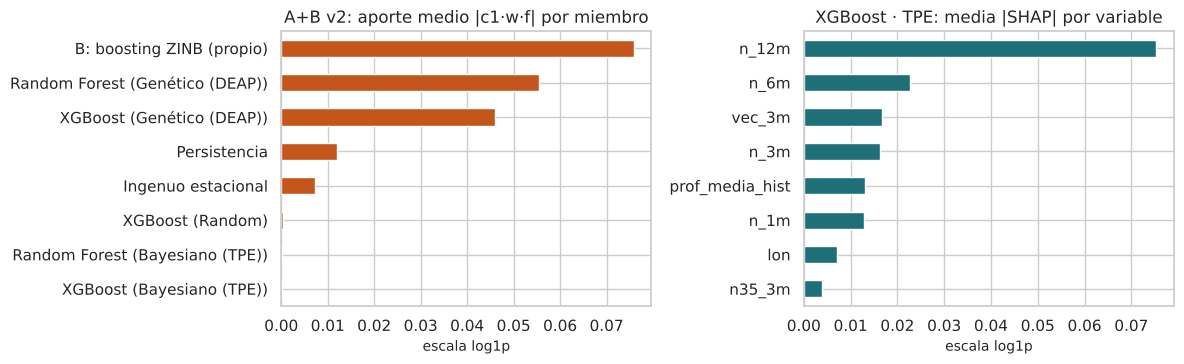

In [12]:
sg = D.shap_global()
a = pd.Series(sg["A+B v2"]["valores"]).drop("calibración (c0)", errors="ignore").head(8)
x = pd.Series(sg["XGBoost · TPE"]["valores"]).head(8)
fig, axs = plt.subplots(1, 2, figsize=(12, 3.8))
a[::-1].plot.barh(ax=axs[0], color="#c4561b"); axs[0].set(title="A+B v2: aporte medio |c1·w·f| por miembro", xlabel="escala log1p")
x[::-1].plot.barh(ax=axs[1], color="#1f6f78"); axs[1].set(title="XGBoost · TPE: media |SHAP| por variable", xlabel="escala log1p")
plt.tight_layout(); plt.show()

## 5.12 Dónde no gana

- **Frente al stacking lineal** con los mismos miembros: empate estadístico (sección 5.10).
- **Mes a mes:** no supera al mejor campeón en todos los meses (proporción en el capítulo 6); pierde sobre todo en meses
  con enjambres o grandes secuencias de réplicas, que ningún modelo anticipa.
- **Magnitud:** su ventaja frente a XGBoost y Random Forest es estadísticamente significativa pero pequeña
  (≈ 0,3–0,6 % de RMSLE).

## 5.13 Comparación con métodos recientes del estado del arte

Además de los 7 benchmarks del curso, A+B se compara con LightGBM, CatBoost y un boosting por histogramas con pérdida de
Poisson, con el **mismo protocolo y el mismo presupuesto**: optimización bayesiana (TPE) de 15 evaluaciones con datos
anteriores a 2016 y origen móvil 2021–2026 (`scripts/estado_del_arte.py`).

In [13]:
ruta = cfg.RESULTADOS / "e3" / "estado_del_arte" / "comparacion.csv"
if ruta.exists():
    SA = pd.read_csv(ruta)
    display(tabla(SA, dec=4))
    md("**Lectura.** " + "; ".join(f"{r['método']}: {r.veredicto} (p de Holm = {r['p Holm (3)']:.3f})" for _, r in SA.iterrows()) + ".")

,método,RMSLE rival,RMSLE A+B,dif. pérdida (rival − A+B),p DM,d de Cohen,p Holm (3),veredicto
0,LightGBM,"0,3264","0,3260","0,0002","0,2549","0,1041","0,2549",sin diferencia significativa
1,CatBoost,"0,3278","0,3260","0,0011","0,1235","0,1795","0,2469",sin diferencia significativa
2,HGB Poisson,"0,3382","0,3260","0,0081","0,0000","0,9406","0,0000",A+B mejor


**Lectura.** LightGBM: sin diferencia significativa (p de Holm = 0.255); CatBoost: sin diferencia significativa (p de Holm = 0.247); HGB Poisson: A+B mejor (p de Holm = 0.000).